# Numerical Analysis

In [27]:
import numpy as np
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
#convention: do not define f(x) as a global function

## 1.1 Root-Finding
### Theorem 1.1.1
For a real-valued function $f$, continuous on bounded closed interval $[a, b] \epsilon \reals$:  
&emsp; if $f(a)f(b)<0$,  
&emsp; then there exsits $\tau \epsilon [a,b]$  
&emsp; such that $f(\tau)=0$  
  
Construct a series of estimates ${x_0, x_1, x_2,..., x_k}$ that converge on the true solution $\tau$  
Then show that $\lim_{k\to\infty} x_k = \tau$  
  
Let $\varepsilon_k$ be the bound on the error at step k:  $|\tau - x_k|<\varepsilon_k$>  
And because the method converges, the bound on the error is always decreasing: $|\tau-x_k|<|\tau-x_{k-1}>  
Then: \varepsilon_{k+1}<\mu\varepsilon_k$ for some number $\mu\epsilon(0,1)$

### Exercise 1.1.1
Does Theorem 1.1 mean that, if there is a solution to $f(x) = 0$ in $[a, b]$ then $f(a)f(b) \leq 0$? That is, is $f(a)f(b) \leq 0$ a necessary condition for there being a solution to $f(x) = 0$? Give an example that supports your answer.  
  
Meetng the condition implies there is a solution, does the existence of a solution imply meeting the condition? $A \implies B$, does $B \implies A$?  
Answer: no

In [3]:
def f1(x):
    return -x**2 + 3

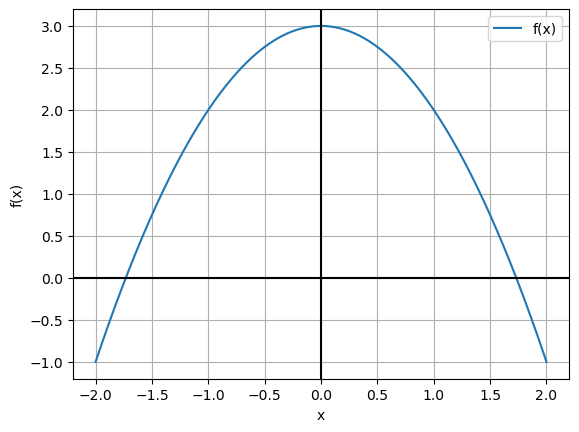

In [4]:
x = np.linspace(-2, 2, 401)  # 401 points between 0 and 3
plt.plot(x, f1(x))
plt.legend(['f(x)', '$\\tau$'])
plt.axhline(0, color='k', linewidth=1.5)  # x-axis
plt.axvline(0, color='k', linewidth=1.5)  # y-axis
plt.xlabel("x"), plt.ylabel("f(x)")
plt.grid(True)

This funciton breaks the condition: for $f(x)$ in $[-2, 2]$, $f(a)f(b)>0$, i.e. $f(a)f(b)$ have the same sign.  
Just becuase they are on teh same side of the axis, doesn;t meant he funciton can't cross it, just means it has to cross back.  
If there is _only_ one $\tau$, then the condition is necessary; if there are multiple $\tau$ then it's not.

## 1.2 Interval Bisection
a.k.a. "The Bisection Method".  
For a function satisfying the conditions of Theorem 1.1.1:  
* Set $x_2$ to be the midpoint of interval $[x_0, x_2]$
* Choose whichever sub-interval $[x_0, x_2]$ or $[x_2, x_1]$ where $f$ changes sign
* Repeat on sub-intervals
  
Because we are reducing the solution space by a factor of 2 with every step k (i.e. scale by $(\frac{1}{2})^k$), then as $k \to \infty$, solution space $2^{-k}\to0 \implies$ convergence.

In [5]:
def bisection(f, a, b, eps):
    eps = 0.001 #stopping criterion
    if abs(f(a)) <= eps:
        return a
    elif abs(f(b)) <= eps:
        return b
    else:
        x_L, x_R = a, b
        k = 1
        cont = True
        while cont:
            x_k = (x_L + x_R)/2
            if f(x_L)*f(x_k) < 0:
                x_R = x_k
            else:
                x_L = x_k
            if f(x_k) <= eps:
                cont = False
                return x_k
            else:
                k += 1
                cont = True

In [39]:
def bisection_plot(f, a, b, eps):
    true_soln = root_scalar(f, bracket=[a, b], xtol=1e-15).root
    x_k_all = [a, b]
    if abs(f(a)) <= eps:
        print(r"\tau = ", a)
    elif abs(f(b)) <= eps:
        print(r"\tau = ", b)
    else:
        x_L, x_R = a, b
        k = 2
        cont = True
        while cont:
            x_k = (x_L + x_R)/2
            x_k_all.append(x_k)
            if f(x_L)*f(x_k) < 0:
                x_R = x_k
            else:
                x_L = x_k
            if abs(f(x_k)) <= eps:
                cont = False
                print(r"\tau = ", x_k)
            else:
                k += 1
                cont = True
    print("k = ", k)

    x = np.linspace(a, b, 401)
    plt.plot(x, f(x))
    plt.plot(x_k_all[:-1], [0]*(len(x_k_all)-1), "^", color = "gray")
    plt.plot(x_k_all[-1], [0], "^", color = "r")
    plt.legend(['f(x)', '$x_k$','$\\tau$'])
    plt.axhline(0, color='k', linewidth=1.5)  # x-axis
    plt.axvline(0, color='k', linewidth=1.5)  # y-axis
    plt.xlabel("x"), plt.ylabel("f(x)")
    plt.xlim(a,b)
    plt.grid(True)
    plt.show()

    k_all = range(k+2)
    fxk_all = [f(xk) for xk in x_k_all]
    err_bound = [abs(true_soln - xk) for xk in x_k_all]

    df = pd.DataFrame(zip(k_all, x_k_all, fxk_all, err_bound), columns = ["k", "x_k", "|f(x_k)|", "|tau - x_k|"])
    print(df.to_string(index = False))

\tau =  1.73193359375
k =  13


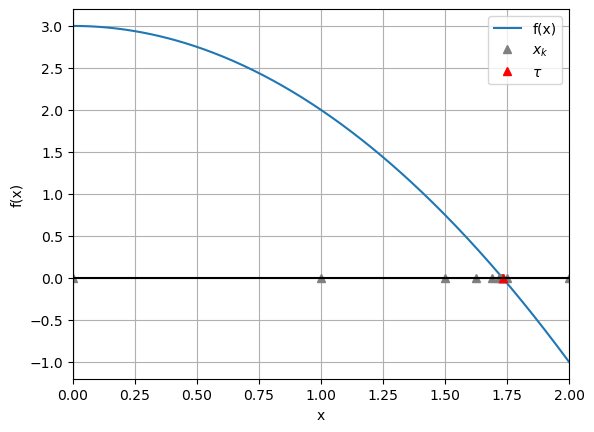

 k      x_k  |f(x_k)|  |tau - x_k|
 0 0.000000  3.000000     1.732051
 1 2.000000 -1.000000     0.267949
 2 1.000000  2.000000     0.732051
 3 1.500000  0.750000     0.232051
 4 1.750000 -0.062500     0.017949
 5 1.625000  0.359375     0.107051
 6 1.687500  0.152344     0.044551
 7 1.718750  0.045898     0.013301
 8 1.734375 -0.008057     0.002324
 9 1.726562  0.018982     0.005488
10 1.730469  0.005478     0.001582
11 1.732422 -0.001286     0.000371
12 1.731445  0.002097     0.000605
13 1.731934  0.000406     0.000117


In [40]:
bisection_plot(f1, 0, 2, 0.001)

In [23]:
def f2(x):
    return x**2 - 2

\tau =  1.4140625
k =  8


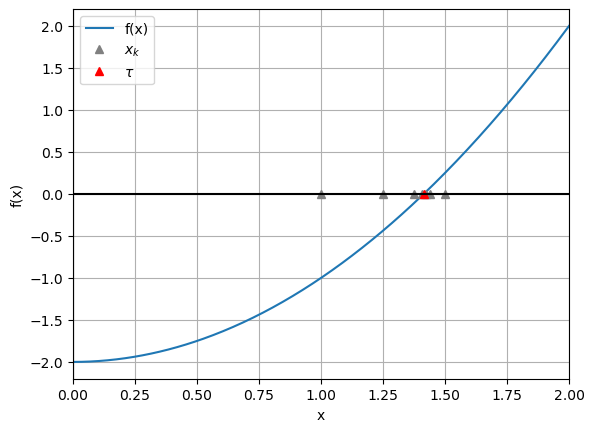

In [24]:
bisection_plot(f2, 0, 2, 0.001)

### Theorem 1.2.1
Let $x_k$ be the $k$th iteration generated by the Bisection Method. Then:
$$ |\tau = x_0| \leq (\frac{1}{2})^{k-1}|b-a| \text{, for } k = 2, 3, 4, ... $$